# 01 - Train all 8 classes: how much of our own (Mae Suai) data do we need?
- **Train on:** all OpenEarthMap (OEM) images + **0% / 25% / 50% / 100%** of our Mae Suai images (these are the **seen** images).
- **Test on:** the Mae Suai images **not** used for training (the **unseen** share): 0% -> 100% unseen, 25% -> 75% unseen, 50% -> 50% unseen. At 100% nothing is unseen, so the score is measured on the training images (fit only, not generalization).
- Image and mask are matched by **same file name** (`1.tif` image <-> `1.tif` mask in `own_paired`; notebook 01 section 2 makes this folder).
- **8 classes:** bareland, rangeland, developed_space, road, tree, water, agriculture, building (mask values 1 to 8).
- All settings (classes, model, training) come from `configs/land_cover_8class.yaml`. To switch model, change `model.active` there.
- The code lives in `src/` (data, models, training, plots). This notebook only sets the options, runs the training and draws the results.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, json
import torch
import pandas as pd
REPO_DIR = r"C:\land_cover_senior2026"
os.chdir(REPO_DIR); sys.path.insert(0, REPO_DIR)

from src.train import load_config
from src.data.paths import resolve_paths
from src.data.pairing import pair_folder, shuffle_pairs, split_for
from src.data.seg_dataset import get_oem_ids
from src.experiments.oem_fraction import run_fraction, run_kfold, summarize_kfold
from src.visualization.plots import (print_table, plot_miou, plot_confusions, plot_iou_heatmap,
                                     plot_prediction_by_filename, print_metrics_table, setup_viewer)


cfg = load_config("configs/oem_8class.yaml")

# ---- CHOOSE THE MODEL HERE (no need to edit the yaml) ----
MODEL_CHOICE = "fpn_r34"       # unet_r34 | fpn_r34 | fpn_swin_b
assert MODEL_CHOICE in cfg["models"], f"pick one of {list(cfg['models'])}"
cfg["model"]["active"] = MODEL_CHOICE

# ---- the options you can change ----
FRACTIONS = [0.0, 0.25, 0.5, 0.75, 1.0]         # share of each fold's training pool used (seen) in training
K = cfg["train"].get("kfold", 5)                # number of rotating test folds (set `kfold:` under `train:` in the yaml)

P = resolve_paths(cfg)
CLASSES    = cfg["classes"]
MODEL_NAME = cfg["model"]["active"]
SEED       = cfg["train"]["seed"]
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| model:", MODEL_NAME, "|", cfg["models"][MODEL_NAME], "| classes:", CLASSES, "| folds:", K)

Device: cuda | model: fpn_r34 | {'decoder': 'fpn', 'encoder': 'resnet34', 'encoder_weights': 'imagenet'} | classes: ['bareland', 'rangeland', 'developed_space', 'road', 'tree', 'water', 'agriculture', 'building'] | folds: 5


## 2. Pair images with masks and make the fixed split
Images and masks are matched by the same file name. All Mae Suai images are shuffled once (seed in the yaml) and saved to `results/own_split.json`.
For a fraction `f`, the first `f` of the shuffled list is **seen** (training) and the rest is **unseen** (test). So the 25% images are always inside the 50% images, and those inside the 100% images.

In [2]:
from src.data.pairing import pair_images_and_labels

own_pairs = pair_folder(P["own_images"], P["own_masks"])
oem_pairs = pair_images_and_labels(P["oem_root"])  # scans all OEM regions automatically
print("Mae Suai pairs:", len(own_pairs), "| OEM pairs:", len(oem_pairs))
assert len(own_pairs) > 0, "No Mae Suai pairs - check own_images and own_masks in the yaml"

# preview of the rotating folds (run_kfold builds the real ones when training starts)
n = len(own_pairs)
sizes = [n // K + (1 if i < n % K else 0) for i in range(K)]
print(f"Mae Suai total {n} | {K} folds | test sizes {sizes}")
for i, t in enumerate(sizes):
    pool = n - t
    counts = [round(f * pool) for f in FRACTIONS]
    print(f"  fold {i + 1}: test {t} unseen | pool {pool} | train on {counts} of {pool} at "
          f"{[int(f * 100) for f in FRACTIONS]}%")

OWN_IDS = cfg["mask_ids"]["own"]
OEM_IDS, oem_seen = get_oem_ids(cfg, oem_pairs)
print("own mask ids:", OWN_IDS)
print("oem mask ids:", OEM_IDS, "| values seen in OEM labels:", sorted(oem_seen) if oem_seen else "n/a")

Successfully paired 2687 images with their matching labels across all OEM regions.
Mae Suai pairs: 44 | OEM pairs: 2687
Mae Suai total 44 | 5 folds | test sizes [9, 9, 9, 9, 8]
  fold 1: test 9 unseen | pool 35 | train on [0, 9, 18, 26, 35] of 35 at [0, 25, 50, 75, 100]%
  fold 2: test 9 unseen | pool 35 | train on [0, 9, 18, 26, 35] of 35 at [0, 25, 50, 75, 100]%
  fold 3: test 9 unseen | pool 35 | train on [0, 9, 18, 26, 35] of 35 at [0, 25, 50, 75, 100]%
  fold 4: test 9 unseen | pool 35 | train on [0, 9, 18, 26, 35] of 35 at [0, 25, 50, 75, 100]%
  fold 5: test 8 unseen | pool 36 | train on [0, 9, 18, 27, 36] of 36 at [0, 25, 50, 75, 100]%
own mask ids: {'bareland': [1], 'rangeland': [2], 'developed_space': [3], 'road': [4], 'tree': [5], 'water': [6], 'agriculture': [7], 'building': [8], 'ignore': []}
oem mask ids: {'auto': False, 'bareland': [1], 'rangeland': [2], 'developed_space': [3], 'road': [4], 'tree': [5], 'water': [6], 'agriculture': [7], 'building': [8], 'ignore': []} | v

## 3. Train (one model per option)
This trains one model per option, so it takes a while. Change `FRACTIONS` in section 1 to run fewer.
Same recipe as `train.py` (cross-entropy + Dice, Adam, mixed precision). The score reported is from the **last epoch**, so we do not pick the best epoch using the test images.

In [3]:
all_results = run_kfold(FRACTIONS, cfg, device, oem_pairs, own_pairs, OEM_IDS, OWN_IDS,
                        P["weights_dir"], P["results_dir"], MODEL_NAME, k=K, seed=SEED)


##### FOLD 1/5 | pool 35 | test 9 #####

=== fpn_r34 (Encoder: resnet34 | Decoder: fpn) | 0% | fold 0 ===
Images trained on: 2687 OEM + 0 Mae Suai = 2687 unique images
Samples per epoch (Mae Suai x5 repeat): 2687
Test on 9 held-out Mae Suai images
epoch  1 | train_loss 2.404 | test mIoU 0.011
epoch  2 | train_loss 1.808 | test mIoU 0.057
epoch  3 | train_loss 1.608 | test mIoU 0.095
epoch  4 | train_loss 1.527 | test mIoU 0.056
epoch  5 | train_loss 1.456 | test mIoU 0.013
epoch  6 | train_loss 1.431 | test mIoU 0.045
epoch  7 | train_loss 1.384 | test mIoU 0.014
epoch  8 | train_loss 1.364 | test mIoU 0.027
epoch  9 | train_loss 1.335 | test mIoU 0.070
epoch 10 | train_loss 1.325 | test mIoU 0.032
epoch 11 | train_loss 1.307 | test mIoU 0.100
epoch 12 | train_loss 1.302 | test mIoU 0.033
epoch 13 | train_loss 1.276 | test mIoU 0.025
epoch 14 | train_loss 1.268 | test mIoU 0.071
epoch 15 | train_loss 1.262 | test mIoU 0.017
epoch 16 | train_loss 1.247 | test mIoU 0.056
epoch 17 | trai

## 4. Results (each option is tested on the Mae Suai images it did not see; 100% is tested on its own training images)

Mae Suai in training   folds test imgs  mIoU mean ± std  bareland  rangeland  developed_space    road    tree   water  agriculture  building
  0% (~0 imgs)             5        44    0.102 ± 0.014   0.004   0.005   0.000   0.000   0.202   0.000   0.038   0.018
 25% (~9 imgs)             5        44    0.179 ± 0.044   0.379   0.000     nan   0.004   0.679   0.022   0.087   0.045
 50% (~18 imgs)            5        44    0.243 ± 0.066   0.211   0.000     nan   0.013   0.746   0.080   0.237   0.245
 75% (~26 imgs)            5        44    0.250 ± 0.069   0.214   0.000     nan   0.000   0.740   0.152   0.188   0.170
100% (~35 imgs)            5        44    0.302 ± 0.044   0.176   0.000     nan   0.001   0.756   0.116   0.269   0.179


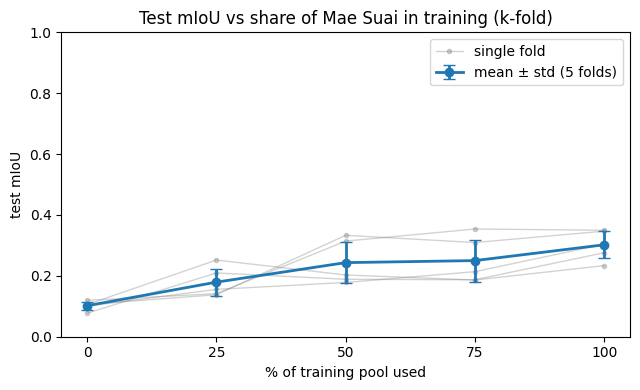

In [5]:
from src.visualization.plots import print_table_kfold, plot_miou_kfold

df_kfold = print_table_kfold(all_results, CLASSES)
plot_miou_kfold(all_results, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_kfold_miou.png")

## 5. Heatmaps: where did it go wrong?
- **Confusion matrices** (one per option): each row is the true class, each column is what the model predicted. Numbers are the % of that true class, so the diagonal is correct and every off-diagonal cell is a specific mistake (e.g. true *road* predicted as *developed_space*).
- **IoU + mIoU heatmap**: one row per option, one column per class and the overall mIoU, for a side-by-side comparison.

fold scores: {0: np.float64(0.19), 1: np.float64(0.256), 2: np.float64(0.247), 3: np.float64(0.196), 4: np.float64(0.188)}
best fold: 1


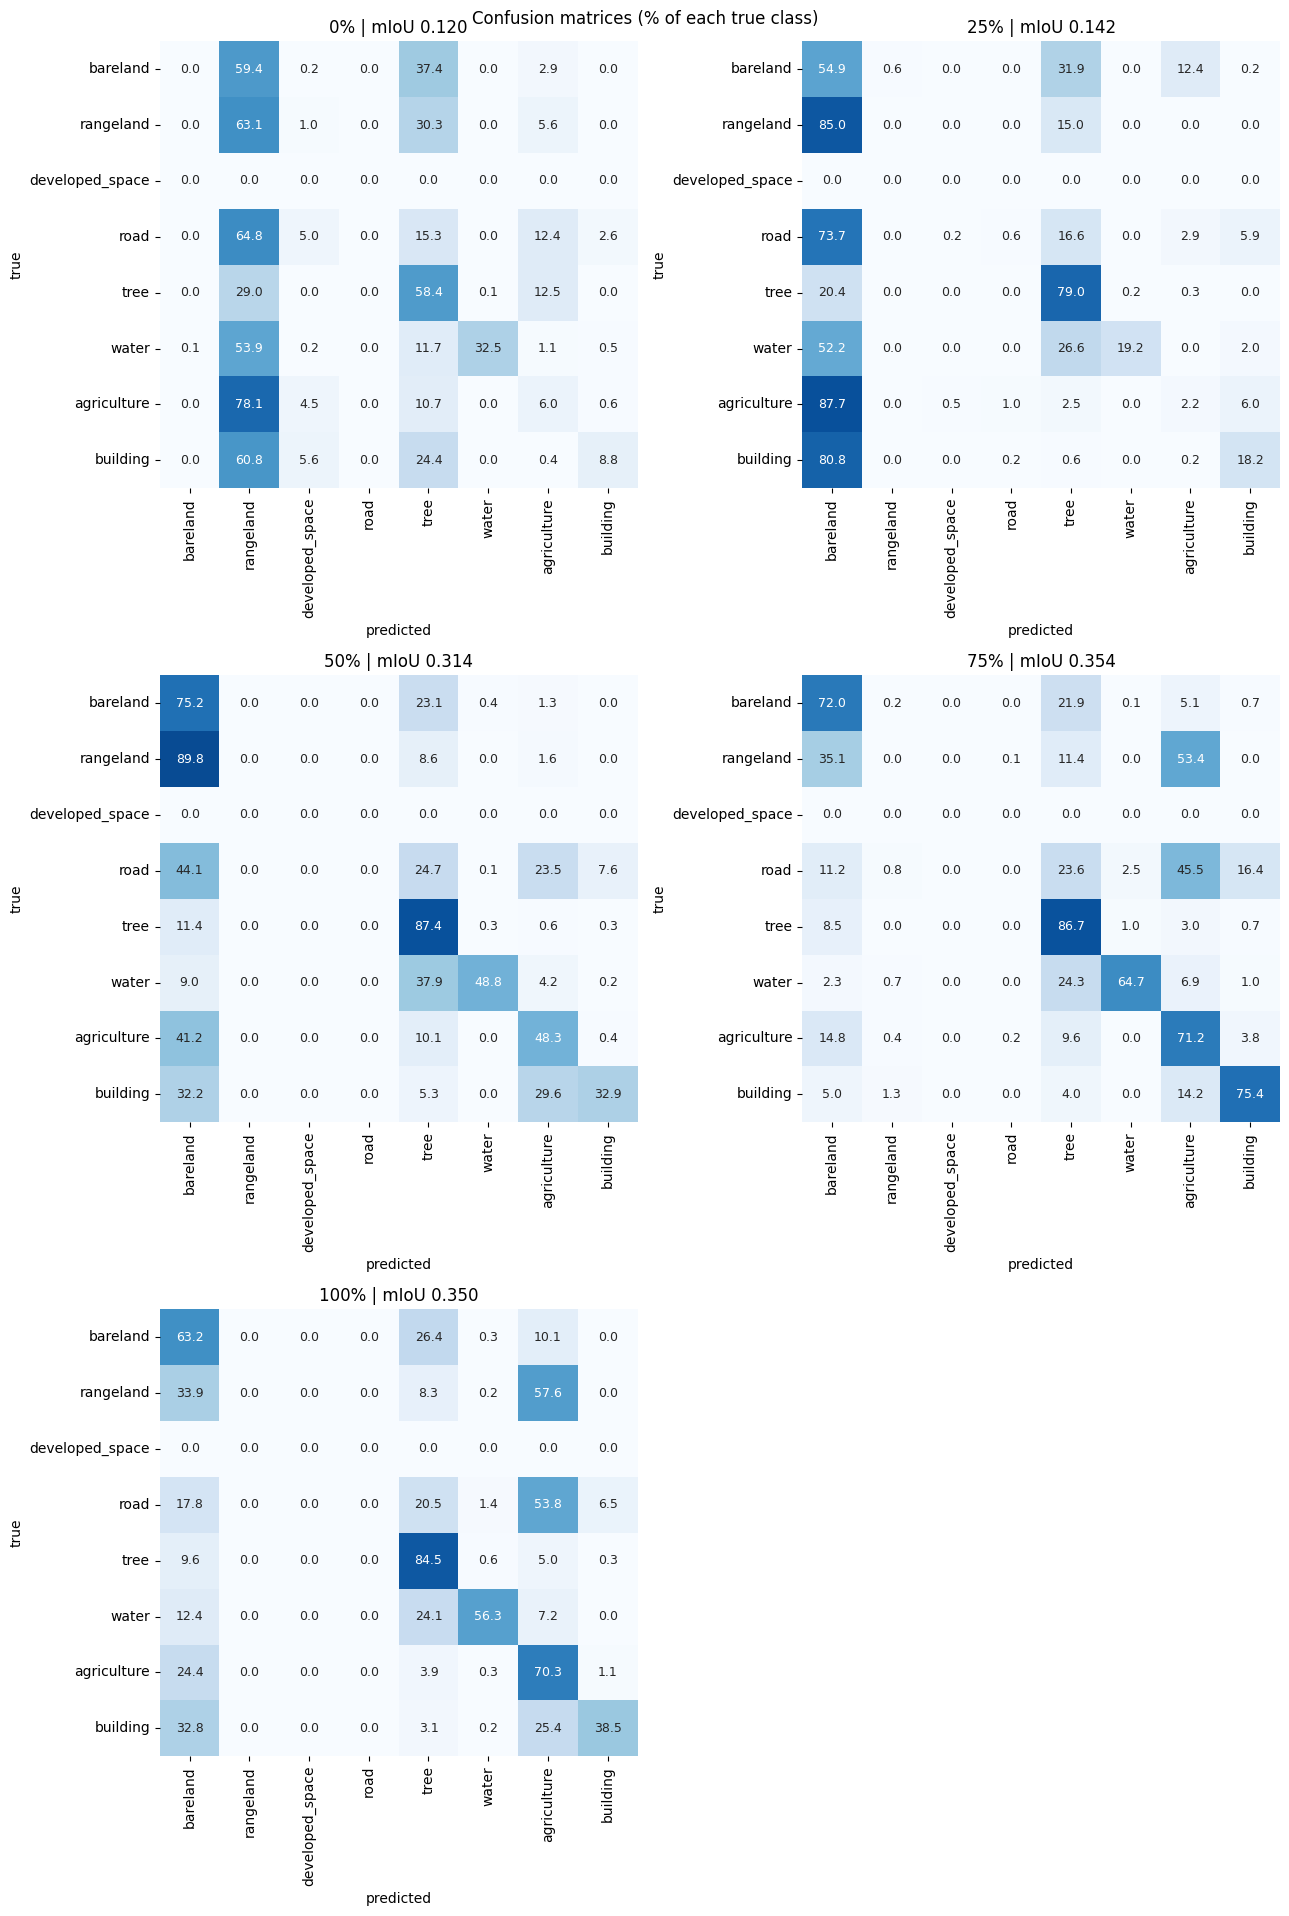

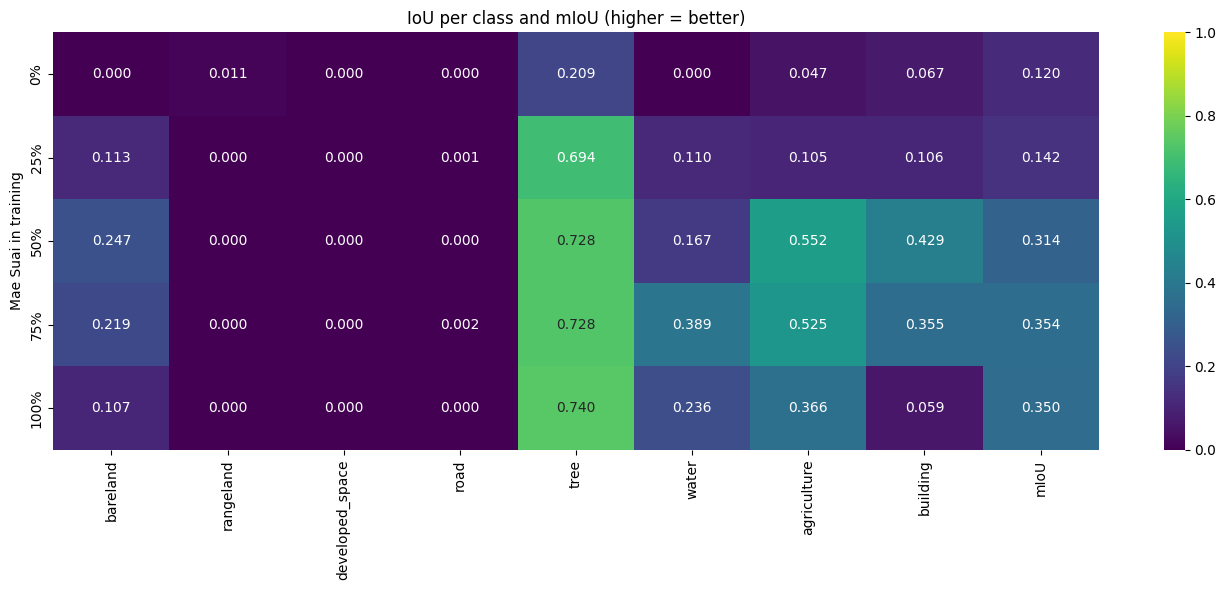

In [7]:
import numpy as np
# fold with the highest mIoU
KEY = "miou"   # same key name you use in summarize_kfold

# score each fold by its average mIoU across all fractions
fold_scores = {k: np.mean([r[KEY] for r in res]) for k, res in all_results.items()}
best_fold = max(fold_scores, key=fold_scores.get)
print("fold scores:", {k: round(v, 3) for k, v in fold_scores.items()})
print("best fold:", best_fold)

results = all_results[best_fold]

plot_confusions(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_confusion_bestfold{best_fold}.png")
plot_iou_heatmap(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_iou_heatmap_bestfold{best_fold}.png")

In [8]:
from src.visualization.plots import print_metrics_table

dfs = []
for k, fold_results in all_results.items():
    print(f"\n--- fold {k} ---")
    d = print_metrics_table(fold_results, CLASSES,
                            save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_metrics_fold{k}.csv")
    d = d.copy()
    d.insert(0, "fold", k)
    dfs.append(d)

# one combined table with every fold
df_all = pd.concat(dfs, ignore_index=True)
df_all.to_csv(P["results_dir"] / f"own_fraction_{MODEL_NAME}_metrics_all_folds.csv", index=False)
df_all


--- fold 0 ---
Mae Suai in training           class  precision  recall    F1   IoU  pixels accuracy
                  0%        bareland      1.000   0.012 0.024 0.012  227824         
                           rangeland      0.010   0.703 0.020 0.010    3441         
                     developed_space      0.000   0.000 0.000 0.000     150         
                                road      0.000   0.000 0.000 0.000    3343         
                                tree      0.843   0.862 0.853 0.743  313548         
                               water      0.000   0.000 0.000 0.000    1392         
                         agriculture      0.097   0.047 0.064 0.033   36203         
                            building      0.010   0.010 0.010 0.005    3923         
                           macro avg      0.245   0.204 0.121 0.100  589824    0.470
                 25%        bareland      0.624   0.583 0.603 0.431  227824         
                           rangeland      0.000  

,fold,Mae Suai in training,class,precision,recall,F1,IoU,pixels,accuracy
0,0,0%,bareland,1.000000,0.011930,0.023579,0.011930,227824,NaN
1,0,0%,rangeland,0.010029,0.702703,0.019776,0.009987,3441,NaN
2,0,0%,developed_space,0.000000,0.000000,0.000000,0.000000,150,NaN
3,0,0%,road,0.000000,0.000000,0.000000,0.000000,3343,NaN
4,0,0%,tree,0.842976,0.862452,0.852603,0.743075,313548,NaN
...,...,...,...,...,...,...,...,...,...
220,4,100%,tree,0.804980,0.690748,0.743502,0.591725,129881,NaN
221,4,100%,water,0.000000,0.000000,0.000000,0.000000,2048,NaN
222,4,100%,agriculture,0.667882,0.347730,0.457345,0.296466,100095,NaN
223,4,100%,building,0.552828,0.609644,0.579848,0.408300,12007,NaN


test images (11):
  [0] 78.tif  [1] 79.tif  [2] 80.tif  [3] 83.tif  [4] 84.tif  [5] 85.tif  [6] 87.tif  [7] 88.tif  [8] 89.tif  [9] 90.tif  [10] 94.tif
loading weights from: C:\land_cover_senior2026\results\weights_8class\fold0
models loaded: ['0%', '25%', '50%', '75%', '100%']
Showing: 85.tif  (dataset index 5)
Model input tensor: shape (3, 256, 256) | min -2.0262 | max 1.7574 | mean -1.3814


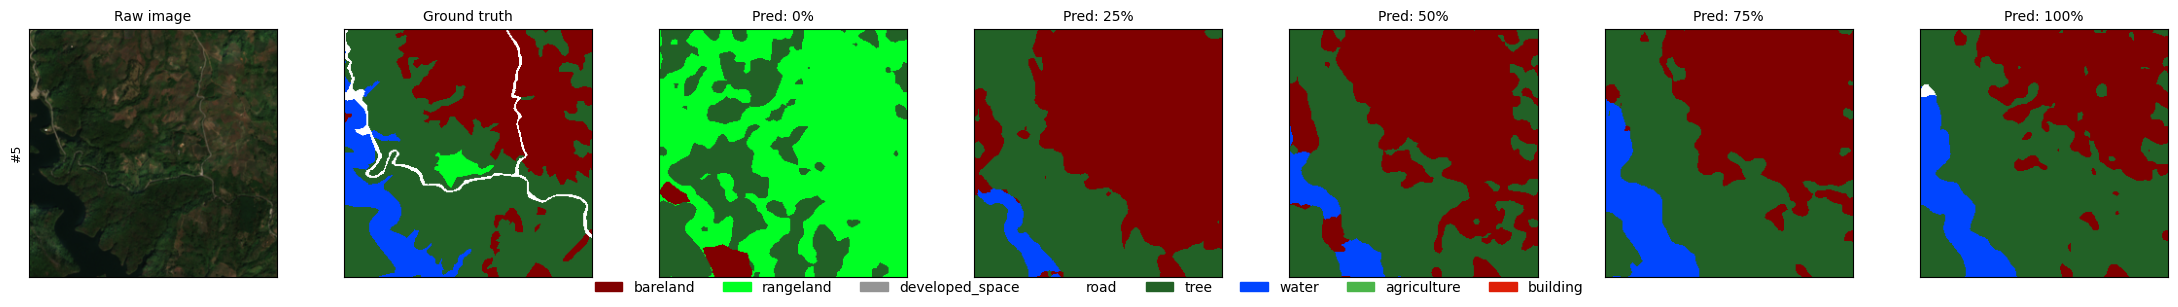

5

In [16]:
from src.visualization.plots import setup_viewer_fold
show = setup_viewer_fold(cfg, own_pairs, OWN_IDS, P, device, fold=0)
show("85.tif")

In [14]:
import os
print(os.listdir(r"C:\land_cover_senior2026\results\weights_8class\fold0"))

['fpn_r34_fraction_0_last.pth', 'fpn_r34_fraction_100_last.pth', 'fpn_r34_fraction_25_last.pth', 'fpn_r34_fraction_50_last.pth', 'fpn_r34_fraction_75_last.pth']


In [17]:
from torch.utils.data import DataLoader
from src.data.seg_dataset import SegDataset

ds = SegDataset(oem_pairs, OEM_IDS, CLASSES, cfg["image_max"]["oem"], cfg["data"]["crop_size"], train=True)
print("pairs:", len(oem_pairs), "| unique images:", len({str(a) for a, _ in oem_pairs}), "| dataset len:", len(ds))

bs = cfg["train"]["batch_size"]
loader = DataLoader(ds, batch_size=bs, shuffle=True, num_workers=0)
seen = sum(x.shape[0] for x, _ in loader)
print("samples in one epoch:", seen, "| batches:", len(loader))

pairs: 2687 | unique images: 2687 | dataset len: 2687
samples in one epoch: 2687 | batches: 336


In [24]:
#BEFORE FIX
import torch
from src.data.seg_dataset import SegDataset

crop = cfg["data"]["crop_size"]
ds_oem = SegDataset(oem_pairs, OEM_IDS, CLASSES, cfg["image_max"]["oem"], crop, train=False)
ds_own = SegDataset(own_pairs, OWN_IDS, CLASSES, cfg["image_max"]["own"], crop, train=False)

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def stats(ds, n=60):
    idx = torch.linspace(0, len(ds) - 1, min(n, len(ds))).long().tolist()
    s = torch.zeros(3); s2 = torch.zeros(3); count = 0
    for i in idx:
        x = ds[i][0].float() * STD + MEAN              # (3, H, W), back to 0-1 brightness
        s  += x.sum((1, 2))
        s2 += (x ** 2).sum((1, 2))
        count += x.shape[1] * x.shape[2]
    mean = s / count
    std = (s2 / count - mean ** 2).sqrt()
    return mean, std

for name, ds in (("OEM", ds_oem), ("Mae Suai", ds_own)):
    m, sd = stats(ds)
    print(f"{name:9s} mean RGB {m.numpy().round(3)} | std RGB {sd.numpy().round(3)}")

OEM       mean RGB [0.467 0.478 0.417] | std RGB [0.207 0.194 0.198]
Mae Suai  mean RGB [0.338 0.393 0.241] | std RGB [0.219 0.148 0.124]


In [20]:
#AFTER FIX
cfg["image_max"]["own"] = 1200
import torch
from src.data.seg_dataset import SegDataset

crop = cfg["data"]["crop_size"]
ds_oem = SegDataset(oem_pairs, OEM_IDS, CLASSES, cfg["image_max"]["oem"], crop, train=False)
ds_own = SegDataset(own_pairs, OWN_IDS, CLASSES, cfg["image_max"]["own"], crop, train=False)

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def stats(ds, n=60):
    idx = torch.linspace(0, len(ds) - 1, min(n, len(ds))).long().tolist()
    s = torch.zeros(3); s2 = torch.zeros(3); count = 0
    for i in idx:
        x = ds[i][0].float() * STD + MEAN              # (3, H, W), back to 0-1 brightness
        s  += x.sum((1, 2))
        s2 += (x ** 2).sum((1, 2))
        count += x.shape[1] * x.shape[2]
    mean = s / count
    std = (s2 / count - mean ** 2).sqrt()
    return mean, std

for name, ds in (("OEM", ds_oem), ("Mae Suai", ds_own)):
    m, sd = stats(ds)
    print(f"{name:9s} mean RGB {m.numpy().round(3)} | std RGB {sd.numpy().round(3)}")

OEM       mean RGB [0.467 0.478 0.417] | std RGB [0.207 0.194 0.198]
Mae Suai  mean RGB [0.416 0.49  0.301] | std RGB [0.258 0.18  0.152]


In [21]:
import torch
clip = torch.zeros(3); total = 0
for i in range(len(ds_own)):
    x = ds_own[i][0].float() * STD + MEAN              # (3, H, W) back to 0-1
    clip += (x >= 0.999).float().sum((1, 2))
    total += x.shape[1] * x.shape[2]
print("pixels at max (R, G, B):", (clip / total * 100).numpy().round(2), "%")

pixels at max (R, G, B): [5.12 1.34 0.33] %


In [ ]:
import json
from src.data.own_split import make_own_folds

pool, test = make_own_folds(own_pairs, K, SEED)[0]
orig_max = cfg["image_max"]["own"]
colour_results = {}

try:
    for own_max in (1200, 1500):
        cfg["image_max"]["own"] = own_max
        wdir = P["weights_dir"] / f"colour_test_{own_max}"; wdir.mkdir(parents=True, exist_ok=True)
        colour_results[own_max] = [
            run_fraction(f, cfg, device, oem_pairs, pool, test, OEM_IDS, OWN_IDS, wdir, fold=0)
            for f in FRACTIONS
        ]
        json.dump(colour_results, open(P["results_dir"] / "colour_test_fold0_results.json", "w"), indent=2)
        print(f"\n===== image_max.own = {own_max} (fold 0) =====")
        print_table(colour_results[own_max], CLASSES)
finally:
    cfg["image_max"]["own"] = orig_max          # put the original value back, even if a run fails


=== fpn_r34 (Encoder: resnet34 | Decoder: fpn) | 0% | fold 0 ===
Images trained on: 2687 OEM + 0 Mae Suai = 2687 unique images
Samples per epoch (Mae Suai x5 repeat): 2687
Test on 9 held-out Mae Suai images
epoch  1 | train_loss 2.402 | test mIoU 0.100


In [ ]:
from src.data.own_split import make_own_folds

FRACTIONS_F1 = [0.0, 0.25, 0.5, 0.75, 1.0]   # 0, 25, 50, 75, 100 %

# fold 1 = index 0
pool, test = make_own_folds(own_pairs, K, SEED)[0]

fold1_results = {}
for frac in FRACTIONS_F1:
    wdir = P["weights_dir"] / f"fold0_frac{int(frac*100)}"
    wdir.mkdir(parents=True, exist_ok=True)

    res = run_fraction(frac, cfg, device, oem_pairs, pool, test,
                       OEM_IDS, OWN_IDS, wdir, fold=0)
    fold1_results[frac] = res

    print(f"\nfraction = {int(frac*100)}% | mIoU {res['miou']:.3f}")
    print({c: round(v, 3) for c, v in zip(CLASSES, res["iou"])})

## Notes
- Each option has a **different test set** (0% tests on all images, 25% on 75%, 50% on 50%), so the scores are not measured on identical images. Small differences can be noise.
- The 100% option has no unseen images, so its score only shows how well the model fits its training data. Do not read it as generalization.
- The split order is listed in `results/own_split.json`. Weights and results files include the model name, so different models do not overwrite each other.
- Before committing to GitHub: *Kernel > Restart & Clear Output*.
- This notebook uses 8 classes, so the confusion matrices are 8x8. Small classes (e.g. road, bareland) usually get a lower IoU than big ones (e.g. tree, rangeland).